# IM subclustering of the pigtail macaque lung atlas

This notebook splits the interstitial macrophage (IM) cluster of the annotated atlas into monocyte-derived IM (Mo-IM), resident IM and cDC2, and removes two low-quality subclusters. It collects the atlas steps from the original working notebooks (`H1N1_and_atlas_work.ipynb` and `atlas_conversion.ipynb`), which produced `atlas_v8.h5ad`.

**Inputs**
- The annotated atlas exported from R (61,467 cells, labels in `cell_type_v5`) as `counts.mtx`, `features.tsv`, `barcodes.tsv`, `cell_metadata.csv` and `umap_coords.csv`
- `IM/im_subclusters_original.csv`, the subcluster of each IM cell in the original run (exported once from the original checkpoint in section 3)

**Outputs** (in `OUT_DIR`)
- `im_subclusters.csv`, the subcluster, label and removal reason for each of the 1,680 IM cells
- `atlas_scanvi_embedding.csv`, the scANVI latent space for the 61,323 final cells
- `atlas_final.h5ad`, the final atlas with raw counts in `X` (gzip-compressed), the original UMAP, the scANVI latent space and `cell_type_final`
- `figures/`, the subcluster UMAP, marker dot plot and QC plots

**Reproducibility.** Loading the saved scANVI model (`LOAD_MODEL = True`) reproduces the original latent space. The neighbor graph, however, depends on the scanpy version, so rerunning Leiden in a different environment gives slightly different subclusters (about 94% of cells received the same final label in a rerun). The labels therefore use the original subcluster assignment, and the rerun is kept as a check (section 7).

## 0. Settings

In [1]:
import os
import sys
from importlib.metadata import version

import numpy as np
import pandas as pd
import scipy.io as sio
import anndata as ad
import scanpy as sc
import scvi

# ── Paths (edit these) ───────────────────────────────────────
EXPORT_DIR     = "/gpfs/projects/kawaldorflab/jcorn427/H1N1_Lung_SC/atlas_export"            # R export of the annotated atlas
MODEL_DIR      = "/gpfs/projects/kawaldorflab/jcorn427/H1N1_Lung_SC/scanvi_reference_atlas"  # saved scANVI model
ORIGINAL_SUBCLUSTERS = "IM/im_subclusters_original.csv"                                       # original IM subclusters
ORIGINAL_IM_CKPT     = "/gpfs/projects/kawaldorflab/jcorn427/H1N1_Lung_SC/checkpoints/atlas_im_v2.h5ad"  # source of that file
ORIGINAL_ATLAS = "/gpfs/projects/kawaldorflab/jcorn427/H1N1_Lung_SC/checkpoints/atlas_v8.h5ad"  # optional check, None to skip
OUT_DIR        = "IM_subclustering_output"

LOAD_MODEL = True   # True loads the saved model, False retrains it

FIG_DIR = os.path.join(OUT_DIR, "figures")
os.makedirs(FIG_DIR, exist_ok=True)
sc.settings.figdir = FIG_DIR
scvi.settings.seed = 42

def clean_obs(obs):
    """Store text columns as categoricals (missing values kept) so they write cleanly to h5ad."""
    obs = obs.copy()
    for col in obs.columns:
        if obs[col].dtype == object:
            s = obs[col]
            obs[col] = pd.Categorical(s.where(s.isna(), s.astype(str)))
    return obs

print("Python", sys.version.split()[0])
for pkg in ["scanpy", "anndata", "scvi-tools", "torch", "leidenalg", "umap-learn", "pynndescent"]:
    try:
        print(pkg, version(pkg))
    except Exception:
        print(pkg, "not installed")

/gpfs/projects/kawaldorflab/software/miniconda3/envs/scANVI/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
[rank: 0] Seed set to 42


Python 3.10.19
scanpy 1.11.5
anndata 0.11.4
scvi-tools 1.3.3
torch 2.9.1
leidenalg 0.10.2
umap-learn 0.5.9.post2
pynndescent 0.5.13


## 1. Load the annotated atlas

The counts are raw (CellBender-corrected) counts. `X_umap` is the original atlas UMAP from R, kept unchanged.

In [2]:
counts   = sio.mmread(os.path.join(EXPORT_DIR, "counts.mtx")).T.tocsr()   # R writes genes x cells
features = pd.read_csv(os.path.join(EXPORT_DIR, "features.tsv"), header=None)[0].astype(str).values
barcodes = pd.read_csv(os.path.join(EXPORT_DIR, "barcodes.tsv"), header=None)[0].astype(str).values
meta     = pd.read_csv(os.path.join(EXPORT_DIR, "cell_metadata.csv"), index_col=0)
umap     = pd.read_csv(os.path.join(EXPORT_DIR, "umap_coords.csv"), index_col=0)

assert counts.shape == (len(barcodes), len(features))
assert (meta.index.astype(str) == barcodes).all()

atlas = ad.AnnData(X=counts, obs=meta, var=pd.DataFrame(index=features))
atlas.obs_names = barcodes
atlas.layers["counts"] = atlas.X.copy()
atlas.obsm["X_umap"] = umap.loc[atlas.obs_names].values

assert atlas.n_obs == 61467 and atlas.n_vars == 21591
print(atlas)
atlas.obs["cell_type_v5"].value_counts()

AnnData object with n_obs × n_vars = 61467 × 21591
    obs: 'orig.ident', 'nCount_RNA', 'nFeature_RNA', 'sample', 'batch', 'gem_group', 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'pct_counts_in_top_50_genes', 'pct_counts_in_top_100_genes', 'pct_counts_in_top_200_genes', 'pct_counts_in_top_500_genes', 'total_counts_mt', 'log1p_total_counts_mt', 'pct_counts_mt', 'doublet_score', 'predicted_doublet', 'leiden', 'leiden_initial', 'scanvi_predictions', 'scanvi_prediction_score', 'cell_type_v0', 'cell_type_v1', 'cell_type_v2', 'sample_id', 'hlca_l1', 'hlca_l1_uncert', 'hlca_l2', 'hlca_l2_uncert', 'hlca_l3', 'hlca_l3_uncert', 'hlca_l4', 'hlca_l4_uncert', 'hlca_l5', 'hlca_l5_uncert', 'rira_fine', 'rira_fine_score', 'rira_lineage', 'rira_lineage_score', 'rira_effector', 'rira_effector_score', 'cell_type_v3', 'cell_type_v4', 'mix_pre', 'mix_scanvi', 'cell_type_v5'
    obsm: 'X_umap'
    layers: 'counts'


cell_type_v5
NEUT           8623
AM             7543
CD4+Tem        5051
cMono          4986
NK             4376
ncMono         4132
CD8+Tem        4058
CAP1           3661
CD8+Tcyto      3078
IM             1680
MAIT-like      1565
Bmem           1191
MESO           1058
Mural           918
Tn              887
FIB             880
Tinn            767
MCC             728
AT2             708
MKI67+T/NK      680
Mast            673
CAP2            600
LEC             472
AT1             471
cDC1            351
MKI67+AM        333
Club            318
Bn              311
pre-TB-SC       289
pDC             226
gdT             218
DCmig           198
CD4+Treg        186
Plasma Cell     156
ILC3             95
Name: count, dtype: int64

## 2. scANVI model of the full atlas

The model learns a latent space that separates the annotated cell types (`cell_type_v5`), with each animal as a batch. It uses the raw counts of all 21,591 genes, 2 layers and 30 latent dimensions. The 130 training epochs are the scvi-tools default for 61,467 cells.

In [3]:
assert "Unknown" not in set(atlas.obs["cell_type_v5"].astype(str))   # placeholder only, no cell is unlabeled

if LOAD_MODEL:
    model = scvi.model.SCANVI.load(MODEL_DIR, adata=atlas)
else:
    scvi.model.SCANVI.setup_anndata(atlas, layer="counts", labels_key="cell_type_v5",
                                    batch_key="sample", unlabeled_category="Unknown")
    model = scvi.model.SCANVI(atlas, n_layers=2, n_latent=30)
    model.train(max_epochs=130)
    model.save(os.path.join(OUT_DIR, "scanvi_atlas_model"), overwrite=True)

atlas.obsm["X_scANVI"] = model.get_latent_representation()

acc = (np.asarray(model.predict()) == atlas.obs["cell_type_v5"].astype(str).values).mean()
print(f"Self-prediction accuracy: {acc:.3f}")   # 0.996 in the original run

INFO     File /gpfs/projects/kawaldorflab/jcorn427/H1N1_Lung_SC/scanvi_reference_atlas/model.pt already downloaded 
Self-prediction accuracy: 0.996


## 3. Subcluster the IM cells

The IM cells are subset, a 15-nearest-neighbor graph is built on the scANVI latent space (the scanpy default) and Leiden clustering is run at resolutions 1.0 and 0.6 on the same graph. Resolution 0.6 was kept after comparing the two (table below).

The rerun subclusters are kept for comparison. The labels in sections 5 and 6 use the original resolution 0.6 assignment, read from `ORIGINAL_SUBCLUSTERS`.

In [4]:
im = atlas[atlas.obs["cell_type_v5"] == "IM"].copy()
assert im.n_obs == 1680

sc.pp.neighbors(im, use_rep="X_scANVI", n_neighbors=15, random_state=0)
sc.tl.umap(im, random_state=0)
sc.tl.leiden(im, resolution=1.0, key_added="rerun_res1.0", flavor="leidenalg", random_state=0)
sc.tl.leiden(im, resolution=0.6, key_added="rerun_res0.6", flavor="leidenalg", random_state=0)

pd.crosstab(im.obs["rerun_res1.0"], im.obs["rerun_res0.6"])

/tmp/ipykernel_2854954/2701183634.py:6: FutureWarning: In the future, the default backend for leiden will be igraph instead of leidenalg.

 To achieve the future defaults please pass: flavor="igraph" and n_iterations=2.  directed must also be False to work with igraph's implementation.
  sc.tl.leiden(im, resolution=1.0, key_added="rerun_res1.0", flavor="leidenalg", random_state=0)


rerun_res0.6,0,1,2,3,4,5,6,7,8
rerun_res1.0,,,,,,,,,
0,239,0,0,5,0,0,0,0,0
1,0,206,1,0,0,0,0,0,0
2,167,5,1,20,0,0,0,0,0
3,1,0,0,161,0,0,0,0,0
4,0,0,0,0,148,5,0,0,0
5,2,0,0,0,0,126,0,0,0
6,0,0,117,1,0,0,1,0,0
7,24,0,0,0,0,0,80,0,0
8,0,0,0,0,0,0,0,94,0


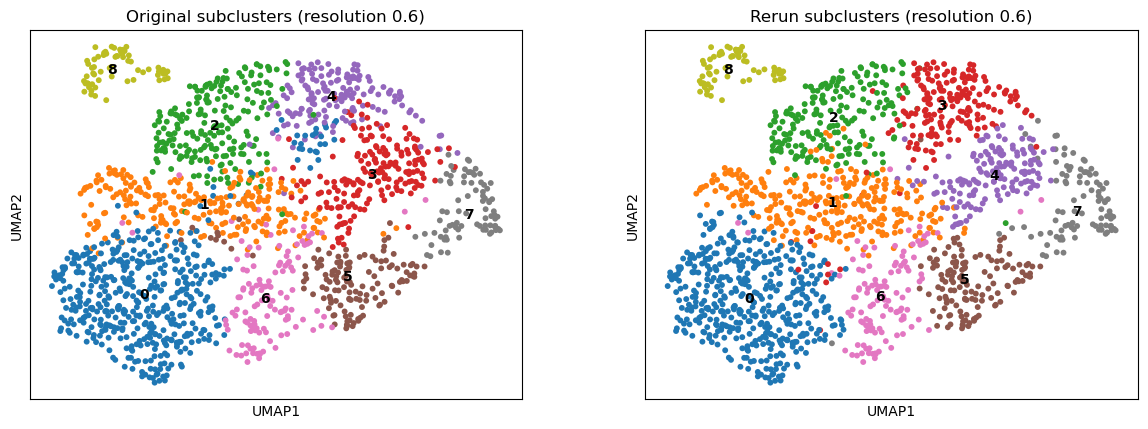

In [5]:
# Original subclusters at resolution 0.6. Exported once from the original checkpoint if the CSV is missing.
if not os.path.exists(ORIGINAL_SUBCLUSTERS):
    ck = ad.read_h5ad(ORIGINAL_IM_CKPT, backed="r")
    os.makedirs(os.path.dirname(ORIGINAL_SUBCLUSTERS), exist_ok=True)
    pd.DataFrame({"cell": ck.obs_names,
                  "subcluster_res0.6": ck.obs["im_subcluster"].astype(str).values}
                 ).to_csv(ORIGINAL_SUBCLUSTERS, index=False)
    ck.file.close()

orig_sub = pd.read_csv(ORIGINAL_SUBCLUSTERS, dtype=str).set_index("cell")["subcluster_res0.6"]
assert set(orig_sub.index) == set(im.obs_names)
im.obs["im_subcluster"] = pd.Categorical(orig_sub.reindex(im.obs_names).values,
                                         categories=[str(i) for i in range(9)])

# Original subcluster sizes. The labels in section 6 are tied to these numbers.
expected = {"0": 485, "1": 244, "2": 213, "3": 183, "4": 152, "5": 135, "6": 124, "7": 80, "8": 64}
sizes = {str(k): int(v) for k, v in im.obs["im_subcluster"].value_counts().items()}
assert sizes == expected, sizes

sc.pl.umap(im, color=["im_subcluster", "rerun_res0.6"], legend_loc="on data",
           title=["Original subclusters (resolution 0.6)", "Rerun subclusters (resolution 0.6)"],
           save="_im_subclusters.pdf")

## 4. Quality and markers of each subcluster

In [6]:
qc = im.obs.groupby("im_subcluster", observed=True).agg(
    cells=("total_counts", "size"),
    median_genes=("n_genes_by_counts", "median"),
    median_UMIs=("total_counts", "median"),
    median_mt_pct=("pct_counts_mt", "median"),
    median_doublet=("doublet_score", "median"),
)
by_animal = pd.crosstab(im.obs["im_subcluster"], im.obs["sample_id"])
qc["top_animal_pct"] = (by_animal.max(axis=1) / by_animal.sum(axis=1) * 100).round(1)
qc.round(3)

,cells,median_genes,median_UMIs,median_mt_pct,median_doublet,top_animal_pct
im_subcluster,,,,,,
0,485,2398.0,6141.0,0.374,0.054,70.7
1,244,2547.5,7506.5,0.481,0.054,39.3
2,213,3417.0,12308.0,0.431,0.054,32.9
3,183,2437.0,6420.0,0.512,0.051,56.8
4,152,3149.5,9745.5,0.338,0.056,30.3
5,135,2717.0,8802.0,0.409,0.061,31.9
6,124,2629.5,7037.0,0.468,0.097,39.5
7,80,1527.0,4589.0,1.429,0.057,87.5
8,64,3902.5,13147.5,0.381,0.093,43.8


In [7]:
by_animal

sample_id,NHP1,NHP2,NHP3,NHP4,NHP5
im_subcluster,,,,,
0,25,38,23,56,343
1,89,23,30,6,96
2,27,30,70,17,69
3,104,6,42,15,16
4,46,18,46,5,37
5,27,26,12,27,43
6,49,9,13,26,27
7,70,3,5,0,2
8,3,28,22,0,11


Not in the reference: []


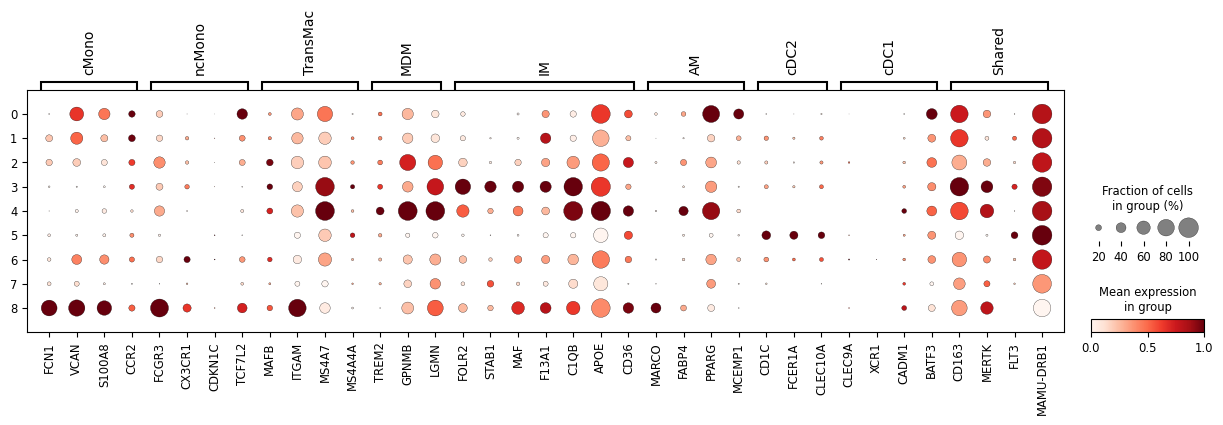

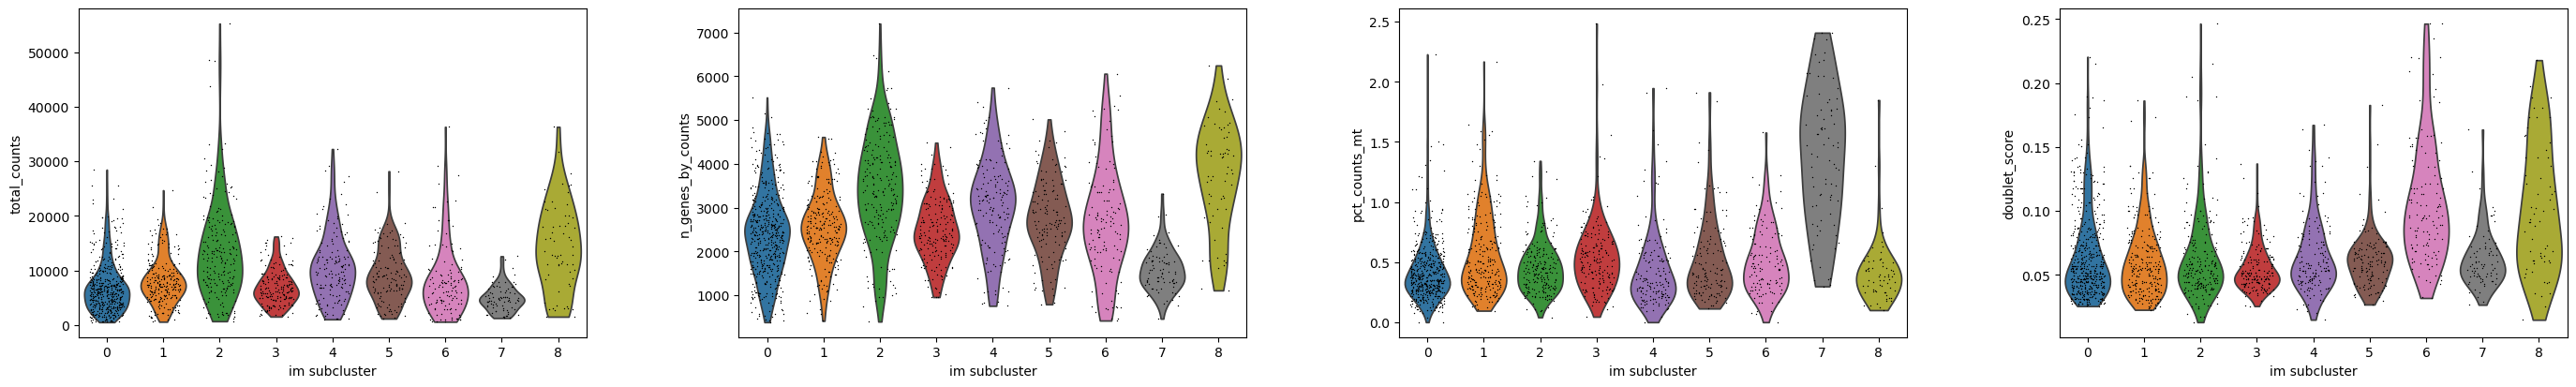

In [8]:
# Log-normalized copy for plotting only (clustering above uses the scANVI latent space)
im_plot = im.copy()
im_plot.X = im_plot.layers["counts"].copy()
sc.pp.normalize_total(im_plot, target_sum=1e4)
sc.pp.log1p(im_plot)

markers = {
    "cMono":    ["FCN1", "VCAN", "S100A8", "CCR2"],
    "ncMono":   ["FCGR3", "CX3CR1", "CDKN1C", "TCF7L2"],
    "TransMac": ["MAFB", "ITGAM", "MS4A7", "MS4A4A"],
    "MDM":      ["TREM2", "GPNMB", "LGMN"],
    "IM":       ["FOLR2", "STAB1", "MAF", "F13A1", "C1QB", "APOE", "CD36"],
    "AM":       ["MARCO", "FABP4", "PPARG", "MCEMP1"],
    "cDC2":     ["CD1C", "FCER1A", "CLEC10A"],
    "cDC1":     ["CLEC9A", "XCR1", "CADM1", "BATF3"],
    "Shared":   ["CD163", "MERTK", "FLT3", "MAMU-DRB1"],
}
missing = [g for genes in markers.values() for g in genes if g not in im_plot.var_names]
print("Not in the reference:", missing)
markers = {k: [g for g in v if g in im_plot.var_names] for k, v in markers.items()}
markers = {k: v for k, v in markers.items() if v}

sc.pl.dotplot(im_plot, markers, groupby="im_subcluster", standard_scale="var",
              save="im_subcluster_markers.pdf")
sc.pl.violin(im_plot, ["total_counts", "n_genes_by_counts", "pct_counts_mt", "doublet_score"],
             groupby="im_subcluster", multi_panel=True, jitter=0.3, save="_im_subcluster_qc.pdf")

## 5. Remove the low-quality and doublet subclusters

Subcluster 7 (80 cells) has the lowest gene counts, a higher mitochondrial fraction than the other subclusters, and 88% of its cells come from one animal (NHP1). Subcluster 8 (64 cells) has the highest gene and UMI counts and expresses monocyte genes (FCN1, VCAN, S100A8, FCGR3) together with macrophage genes (C1QB, MAF, CD36, MARCO), consistent with monocyte and macrophage doublets. Both are removed, 144 cells in total.

In [9]:
removal = {"7": "IM low quality", "8": "IM possible doublets"}
im.obs["removal_reason"] = im.obs["im_subcluster"].astype(str).map(removal)
drop_cells = im.obs_names[im.obs["removal_reason"].notna()]
assert len(drop_cells) == 144
im.obs["removal_reason"].value_counts()

removal_reason
IM low quality          80
IM possible doublets    64
Name: count, dtype: int64

## 6. Name the remaining subclusters

Names follow the marker dot plot. Four subclusters are monocyte-derived IM (Mo-IM, first called tMac), two are resident IM and one is cDC2.

In [10]:
im_labels = {"0": "Mo-IM", "1": "Mo-IM", "2": "Mo-IM", "6": "Mo-IM",
             "3": "IM", "4": "IM",
             "5": "cDC2",
             "7": "Removed", "8": "Removed"}
im.obs["im_label"] = im.obs["im_subcluster"].astype(str).map(im_labels)

n = im.obs["im_label"].value_counts()
assert n.to_dict() == {"Mo-IM": 1066, "IM": 335, "Removed": 144, "cDC2": 135}
n

im_label
Mo-IM      1066
IM          335
Removed     144
cDC2        135
Name: count, dtype: int64

## 7. Check the rerun against the original subclusters

Each rerun subcluster is given the label of the original subcluster it overlaps most, and the labels are compared cell by cell.

In [11]:
tab = pd.crosstab(im.obs["im_subcluster"].astype(str), im.obs["rerun_res0.6"].astype(str),
                  rownames=["original"], colnames=["rerun"])
rerun_to_label = {r: im_labels[tab[r].idxmax()] for r in tab.columns}
im.obs["rerun_label"] = im.obs["rerun_res0.6"].astype(str).map(rerun_to_label)

agree = (im.obs["rerun_label"] == im.obs["im_label"]).mean()
print(f"Cells with the same label in the rerun: {agree:.1%}")
display(pd.crosstab(im.obs["im_label"], im.obs["rerun_label"], rownames=["original"], colnames=["rerun"]))
tab

Cells with the same label in the rerun: 94.1%


rerun,IM,Mo-IM,Removed,cDC2
original,,,,
IM,296,21,12,6
Mo-IM,39,1020,3,4
Removed,0,0,144,0
cDC2,0,14,0,121


rerun,0,1,2,3,4,5,6,7,8
original,,,,,,,,,
0,431,11,3,37,0,0,2,1,0
1,18,224,0,0,0,0,0,2,0
2,0,26,184,2,0,0,1,0,0
3,0,9,0,14,148,5,0,7,0
4,0,1,11,134,0,1,0,5,0
5,0,10,1,0,0,121,3,0,0
6,3,4,2,0,0,4,111,0,0
7,0,0,0,0,0,0,0,80,0
8,0,0,0,0,0,0,0,0,64


## 8. Final atlas

The 144 cells are removed, and `cell_type_final` takes `cell_type_v5` with the three IM labels in place of IM.

In [12]:
final = atlas[~atlas.obs_names.isin(drop_cells)].copy()

im_lab = im.obs["im_label"].astype(object).reindex(final.obs_names)
final.obs["cell_type_final"] = np.where(im_lab.notna(), im_lab, final.obs["cell_type_v5"].astype(str))
final.obs["cell_type_final"] = final.obs["cell_type_final"].astype("category")
final.obs["im_subcluster"] = im.obs["im_subcluster"].astype(str).reindex(final.obs_names)

assert final.n_obs == 61323
assert final.obs["cell_type_final"].nunique() == 37
final.obs["cell_type_final"].value_counts()

cell_type_final
NEUT           8623
AM             7543
CD4+Tem        5051
cMono          4986
NK             4376
ncMono         4132
CD8+Tem        4058
CAP1           3661
CD8+Tcyto      3078
MAIT-like      1565
Bmem           1191
Mo-IM          1066
MESO           1058
Mural           918
Tn              887
FIB             880
Tinn            767
MCC             728
AT2             708
MKI67+T/NK      680
Mast            673
CAP2            600
LEC             472
AT1             471
cDC1            351
IM              335
MKI67+AM        333
Club            318
Bn              311
pre-TB-SC       289
pDC             226
gdT             218
DCmig           198
CD4+Treg        186
Plasma Cell     156
cDC2            135
ILC3             95
Name: count, dtype: int64

## 9. Check against the original `atlas_v8.h5ad` (optional)

Both numbers should be 1 when the saved model is loaded.

In [13]:
if ORIGINAL_ATLAS and os.path.exists(ORIGINAL_ATLAS):
    orig = ad.read_h5ad(ORIGINAL_ATLAS, backed="r")
    orig_labels = orig.obs["cell_type_final"].astype(str).replace({"tMac": "Mo-IM"})
    orig_scanvi = pd.DataFrame(np.asarray(orig.obsm["X_scANVI"]), index=orig.obs_names)
    orig.file.close()

    assert set(orig_labels.index) == set(final.obs_names)
    same = orig_labels.reindex(final.obs_names).values == final.obs["cell_type_final"].astype(str).values
    r = np.corrcoef(orig_scanvi.reindex(final.obs_names).values.ravel(),
                    final.obsm["X_scANVI"].ravel())[0, 1]
    print(f"Label agreement with atlas_v8: {same.mean():.4f}")
    print(f"scANVI correlation with atlas_v8: {r:.4f}")
else:
    print("Skipped (no original atlas given)")

Label agreement with atlas_v8: 1.0000
scANVI correlation with atlas_v8: 1.0000


## 10. Save

In [14]:
im_table = pd.DataFrame({
    "cell": im.obs_names,
    "animal": im.obs["sample_id"].astype(str).values,
    "subcluster_res0.6": im.obs["im_subcluster"].astype(str).values,
    "label": im.obs["im_label"].values,
    "removal_reason": im.obs["removal_reason"].values,
    "rerun_res1.0": im.obs["rerun_res1.0"].astype(str).values,
    "rerun_res0.6": im.obs["rerun_res0.6"].astype(str).values,
})
im_table.to_csv(os.path.join(OUT_DIR, "im_subclusters.csv"), index=False)

emb = pd.DataFrame(final.obsm["X_scANVI"], index=final.obs_names,
                   columns=[f"scANVI_{i + 1}" for i in range(final.obsm["X_scANVI"].shape[1])])
emb.index.name = "cell"
emb.to_csv(os.path.join(OUT_DIR, "atlas_scanvi_embedding.csv"))

final.obs = clean_obs(final.obs)
if "counts" in final.layers:
    del final.layers["counts"]
final.write_h5ad(os.path.join(OUT_DIR, "atlas_final.h5ad"), compression="gzip")

print("Saved to", os.path.abspath(OUT_DIR))
print(" im_subclusters.csv:", len(im_table), "IM cells")
print(" atlas_scanvi_embedding.csv:", emb.shape)
print(" atlas_final.h5ad:", final.n_obs, "cells,", final.n_vars, "genes")

Saved to /gpfs/projects/kawaldorflab/tykim/python_files/Lung_Atlas/IM_subclustering_output
 im_subclusters.csv: 1680 IM cells
 atlas_scanvi_embedding.csv: (61323, 30)
 atlas_final.h5ad: 61323 cells, 21591 genes
